# Isothermal contours and the downstream mean-free-path / tail-length comparison

Saved analytical curves ($\xi=-0.85$), warm numerical curves, and accepted cold numerical dots are retained from `26-10-02.ipynb`. No contour or numerical front is recalculated here.

The separate calculation compares, at the **static pressure-matched equilibrated quark endpoint** ($T$ common, $P(\infty)=P(0^-)$, $\mu_K(\infty)=0$),

$$\lambda_{\mathrm{mfp}}=3D_K,\qquad L_{\mathrm{conv}}=\frac{\mu_B(\infty)}{9\pi T}\sqrt{\frac{D_K}{\gamma_K}}.$$

The default is $\lambda_{\mathrm{mfp}}=L_{\mathrm{conv}}$. Change `MFP_FRACTION` to `0.1` for ten percent. Both are expected to have **no crossing** in this window: the estimated ratio is of order $10^{-7}$–$10^{-6}$, not order unity. The calculation reports sampled ratios and any failed EOS states explicitly; a failed evaluation is not evidence of no crossing.

This is the manuscript's constant-background **downstream thermal tail**, not the appendix's local diffusion-gradient criterion $\lambda_{\mathrm{mfp}}<D_K/|dD_K/dx|$. For fixed $\mu_B(\infty)$, the leading Landau expression gives $\lambda_{\mathrm{mfp}}/L_{\mathrm{conv}}\propto T^{1/6}$, even though the individual lengths diverge as $T\to0$.

Run the three cells below in order. Changing only plot styling requires rerunning only the last cell. Completed EOS evaluations are saved before progress advances and reused when changing the fraction or diffusion choice. Original datasets and `RMFsolver` are read-only.

In [1]:
# Saved-data loading only: no velocity calculation or BVP calls.
from pathlib import Path
from collections import Counter
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'RMFsolver').is_dir():
    raise RuntimeError('Open this notebook with NSM_related as its working directory')
for relative in ('new_paper_calculations/26-10-02', 'new_paper_calculations/26-10-14'):
    directory = str(ROOT / relative)
    if directory not in sys.path:
        sys.path.insert(0, directory)
import notebook_isothermal
import notebook_isothermal_cold
import _saved_contour_data as saved_data
import isothermal_mfp
isothermal_mfp = importlib.reload(isothermal_mfp)

OUTPUT_DIRECTORY = ROOT / 'local_analysis_results/26-10-14'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
SAVED_DIRECTORY = ROOT / 'local_analysis_results/26-10-02'
CHECKPOINT_PATH = SAVED_DIRECTORY / 'isothermal-notebook-run/isothermal-analytic-logT.npy'
warm_data, numerical_logT, cold_endpoints, warm_manifest = notebook_isothermal.load_numerical(ROOT)
boundary_inputs = notebook_isothermal.load_boundary_inputs(ROOT)
assert boundary_inputs['fingerprint'] == warm_manifest['domain_fingerprint']
for name in ('B_one_forth', 'ms', 'NM_type', 'upB'):
    assert boundary_inputs['physics'][name] == numerical_logT['identity']['physics'][name]
if CHECKPOINT_PATH.exists():
    isothermal_analytic = np.load(CHECKPOINT_PATH, allow_pickle=True).item()
    print('Saved analytical checkpoint:', CHECKPOINT_PATH.relative_to(ROOT))
else:
    isothermal_analytic = notebook_isothermal.load_reference(ROOT)
assert isothermal_analytic['domain_fingerprint'] == boundary_inputs['fingerprint']
# Load optional extra cold numerical dots without invoking their calculation code.
for payload_name, filename in (
    ('cold_numerical_extra', 'isothermal-cold-numerical-points.npy'),
    ('cold_numerical_high', 'isothermal-cold-numerical-high-speed.npy'),
    ('cold_numerical_high_fallback', 'isothermal-cold-numerical-high-speed-fallback.npy'),
):
    globals().pop(payload_name, None)
    path = SAVED_DIRECTORY / filename
    if path.exists():
        globals()[payload_name] = np.load(path, allow_pickle=True).item()
print('Saved analytical targets:', dict(Counter(r['status'] for r in isothermal_analytic['targets'].values())))
print('Loaded warm numerical curves and accepted cold dots; no contours recalculated.')
mfp_result = None  # Set by the next cell; avoids accidentally plotting an old fraction.


Saved analytical checkpoint: local_analysis_results/26-10-02/isothermal-notebook-run/isothermal-analytic-logT.npy
Saved analytical targets: {'success': 604, 'unresolved': 1, 'outside_window': 39}
Loaded warm numerical curves and accepted cold dots; no contours recalculated.


## Static EOS calculation

46 temperature slices by default; only bracketed density roots are solved. One bounded worker, no BVP runs. Endpoint sampling can be increased with `DENSITY_SAMPLES`. Existing no-crossing slices and failures resume without repeating work.

In [ ]:
# Tunable mean-free-path calculation parameters (no plotting)
MFP_FRACTION = 1.0  # 1.0 = 100%; 0.1 = 10%. Neither is expected to cross in this window.
DIFFUSION_APPROXIMATION = 'full'  # 'full' or leading 'landau'; applies to BOTH lengths.
MFP_TEMPERATURES = tuple(notebook_isothermal.TEMPERATURES)  # Existing 46 temperatures.
DENSITY_SAMPLES = 2  # Evaluate the saved allowed interval endpoints before root finding.
RATIO_RELATIVE_TOLERANCE = 1.e-6
MAX_EVALUATIONS_PER_TEMPERATURE = 40
TRIAL_TIMEOUT_SECONDS = 60.
TEMPERATURE_TIMEOUT_SECONDS = 180.
WORKER_IMPORT_PATHS = None  # Auto-select the existing isolated SciPy runtime, if available.
MFP_RUN_DIRECTORY = OUTPUT_DIRECTORY / 'mfp-static-tail'

# One bounded EOS worker, one BLAS thread; NO moving-front or contour calculation.
# Fractions and diffusion choices share an independent thermodynamic cache.
# Terminal failures are retained. Use a new MFP_RUN_DIRECTORY for an explicit retry.
isothermal_mfp = importlib.reload(isothermal_mfp)
mfp_result = isothermal_mfp.calculate(
    boundary_inputs, MFP_RUN_DIRECTORY,
    fraction=MFP_FRACTION, diffusion=DIFFUSION_APPROXIMATION,
    temperatures=MFP_TEMPERATURES, density_samples=DENSITY_SAMPLES,
    ratio_rtol=RATIO_RELATIVE_TOLERANCE, max_evaluations=MAX_EVALUATIONS_PER_TEMPERATURE,
    trial_timeout=TRIAL_TIMEOUT_SECONDS, temperature_timeout=TEMPERATURE_TIMEOUT_SECONDS,
    import_paths=WORKER_IMPORT_PATHS)
isothermal_mfp.report(mfp_result)
print('Saved result:', mfp_result['result_path'])


## Visualization from saved / calculated results

Black dash-dot segments appear only for validated roots on consecutive scheduled temperatures. Missing, failed, and no-crossing slices break the overlay. No solver calls occur in this cell.

MFP calculation has not been run in this kernel; showing saved contours only.
Saved local_analysis_results/26-10-14/isothermal-contours-mfp-tail.png
Saved local_analysis_results/26-10-14/isothermal-contours-mfp-tail.pdf


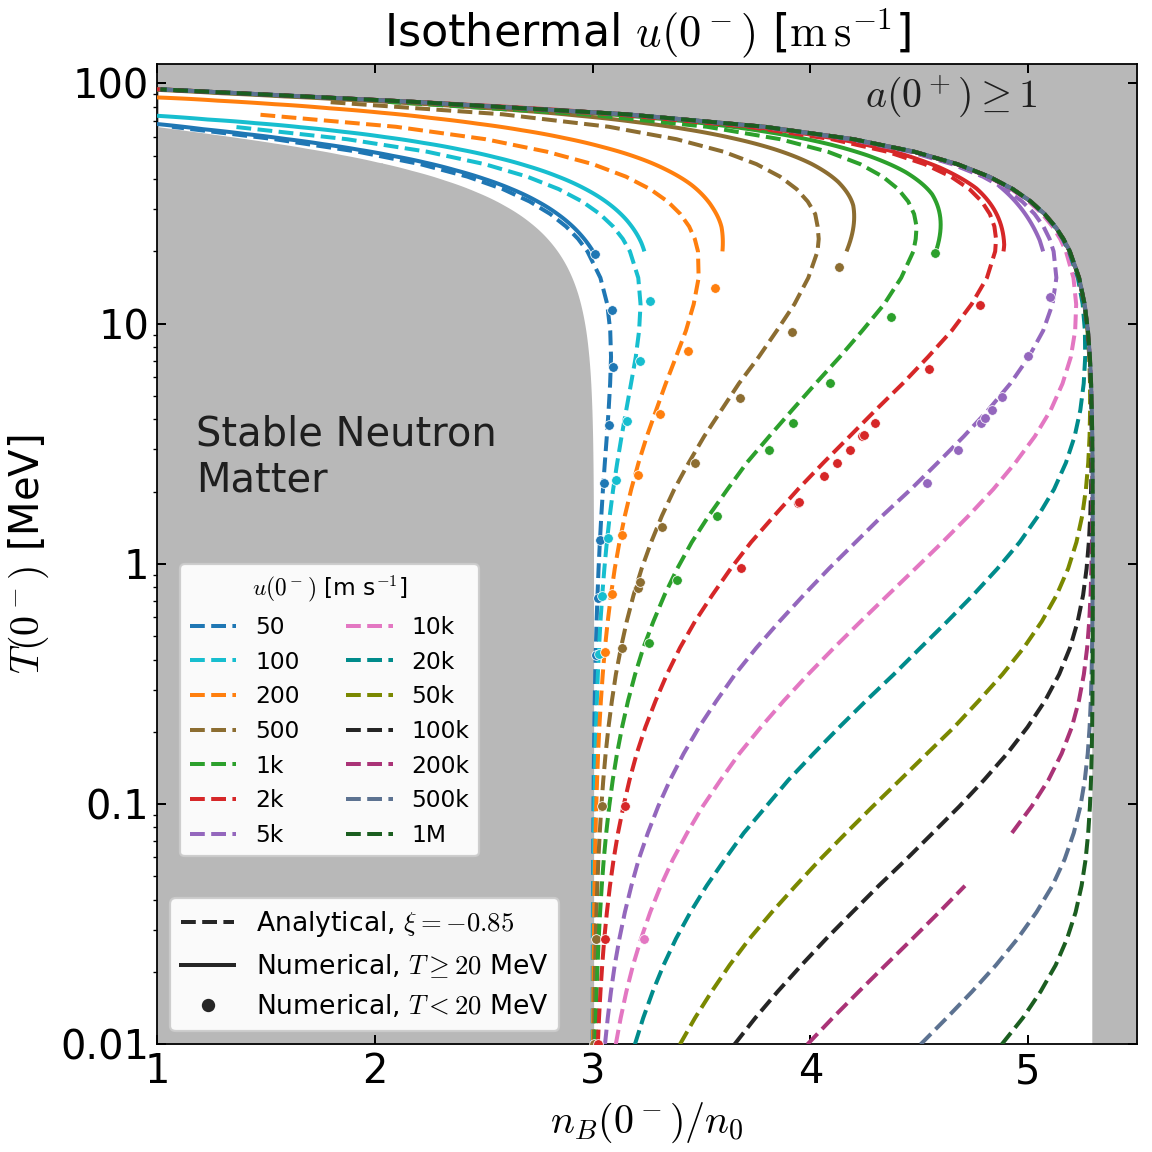

In [2]:
# Tunable plotting parameters
CONTOUR_LEVELS = (50., 100., 200., 500., 1000., 2000., 5000., 10000., 20000., 50000., 100000., 200000., 500000., 1000000.)
CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd', '#e377c2', '#008b8b', '#7a8800', '#252525', '#aa3377', '#5c7291', '#1b5e20')
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = 'white'
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BOX_ASPECT = 1.
X_LIMITS = (1., 5.5)
Y_LIMITS = (.01, 120.)
X_SCALE = 'linear'
Y_SCALE = 'log'
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS = (.01, .1, 1., 10., 100.)
Y_TICK_LABELS = ('0.01', '0.1', '1', '10', '100')
TITLE = r'Isothermal $u(0^-)$ [$\mathrm{m\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r'$n_B(0^-)/n_0$'
Y_LABEL = r'$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LINE_WIDTH = 1.8
ANALYTICAL_ZORDER = 4
NUMERICAL_ZORDER = 3
NUMERICAL_SPLIT_TEMPERATURE = 20.
NUMERICAL_MARKER = 'o'
MARKER_SIZE = 19.
MARKER_EDGE_COLOR = 'white'
MARKER_EDGE_WIDTH = .35
MARKER_ALPHA = 1.
MARKER_ZORDER = 5
ISOLATED_ANALYTICAL_MARKER = 'x'
ISOLATED_ANALYTICAL_SIZE = 15.
LABEL_CURVES = False
CONTOUR_LABEL_FONT_SIZE = 12
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
CONTOUR_LABEL_BACKGROUND_ALPHA = .92
CONTOUR_LABEL_BACKGROUND_PAD = .12
CONTOUR_LABEL_BACKGROUND_STYLE = 'round'
CONTOUR_LABEL_EDGE_COLOR = 'none'
CONTOUR_LABEL_ZORDER = 6
LABEL_TEMPERATURES = {50.: 44., 100.: 50., 200.: 57., 500.: 53., 1000.: 43., 2000.: 31., 5000.: 25.}
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
INNER_REGION_TEXT = 'Stable Neutron\nMatter'
INNER_REGION_POSITION = (1.18, 2.)
OUTER_REGION_TEXT = r'$a(0^+)\geq1$'
OUTER_REGION_POSITION = (4.25, 80.)
REGION_TEXT_COLOR = '0.12'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 6
LEGEND_LOCATION = 'lower left'
LEGEND_FONT_SIZE = 12
LEGEND_FRAME_ALPHA = .94
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
LEGEND_HANDLE_COLOR = '0.15'
LEGEND_MARKER_SIZE = 5.
LEGEND_LABELS = (rf"Analytical, $\xi={isothermal_analytic['identity']['physics']['xi']:g}$", r'Numerical, $T\geq20$ MeV', r'Numerical, $T<20$ MeV')
SHOW_SPEED_LEGEND = True
SPEED_LEGEND_LOCATION = 'lower left'
SPEED_LEGEND_TITLE = r'$u(0^-)$ [m s$^{-1}$]'
SPEED_LEGEND_FONT_SIZE = 10.5
SPEED_LEGEND_COLUMNS = 2
SPEED_LEGEND_ANCHOR = (.012, .18)
SPEED_LABELS = ('50', '100', '200', '500', '1k', '2k', '5k', '10k', '20k', '50k', '100k', '200k', '500k', '1M')
SHOW_GRID = False
EXPORT_STEM = 'isothermal-contours-mfp-tail'
EXPORT_FORMATS = ('png', 'pdf')
MFP_COLOR = 'black'
MFP_LINE_STYLE = '-.'
MFP_LINE_WIDTH = 2.0
MFP_ALPHA = 1.0
MFP_ZORDER = 7
MFP_ISOLATED_MARKER = 's'
MFP_ISOLATED_MARKER_SIZE = 20.
MFP_LEGEND_LOCATION = 'upper right'
MFP_LEGEND_FONT_SIZE = 10.5
MFP_LABEL = (rf"$\lambda_{{\mathrm{{mfp}}}}={mfp_result['controls']['fraction']:g}L_{{\mathrm{{conv}}}}$"
             if mfp_result is not None else '')

from matplotlib.lines import Line2D
from matplotlib.contour import ContourSet

with plt.rc_context({'font.family': FONT_FAMILY, 'mathtext.fontset': MATH_FONT_SET,
                     'text.usetex': USE_TEX}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                               constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    for side, (temperatures, densities, edge) in saved_data.shading_boundaries(
            warm_data, isothermal_analytic, Y_LIMITS, X_LIMITS).items():
        shade = axis.fill_betweenx(temperatures, densities, edge, color=EXCLUDED_REGION_COLOR,
                                  alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
        shade.set_gid(f'excluded:{side}')
    warm_segments, label_positions = [], []
    for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS):
        # Each run stops at an unresolved or out-of-window scheduled target.
        for segment in saved_data.analytical_segments(isothermal_analytic, level):
            if len(segment) >= 2:
                axis.plot(segment[:, 0], segment[:, 1], color=color,
                          linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                          zorder=ANALYTICAL_ZORDER, gid=f'analytical:{level:g}')
            else:
                axis.scatter(segment[:, 0], segment[:, 1], color=color,
                             marker=ISOLATED_ANALYTICAL_MARKER, s=ISOLATED_ANALYTICAL_SIZE,
                             zorder=ANALYTICAL_ZORDER, gid=f'analytical-isolated:{level:g}')
        dots = saved_data.cold_numerical_points(warm_data, numerical_logT, cold_endpoints,
                                               level, NUMERICAL_SPLIT_TEMPERATURE)
        # Additional roots are accepted saved numerical data, loaded without a BVP run.
        for payload_name in ('cold_numerical_extra', 'cold_numerical_high', 'cold_numerical_high_fallback'):
            if payload_name in globals():
                extra_dots = notebook_isothermal_cold.new_points(globals()[payload_name], level)
                dots = np.unique(np.vstack((dots, extra_dots)), axis=0)
        if len(dots):
            axis.scatter(dots[:, 0], dots[:, 1], color=color, marker=NUMERICAL_MARKER,
                         s=MARKER_SIZE, edgecolors=MARKER_EDGE_COLOR, linewidths=MARKER_EDGE_WIDTH,
                         alpha=MARKER_ALPHA, zorder=MARKER_ZORDER, gid=f'numerical-cold:{level:g}')
        # Warm numerical curves exist only at the archived levels.
        if level not in warm_data['levels_m_s']:
            continue
        index = list(warm_data['levels_m_s']).index(level)
        curve = saved_data.warm_curve(warm_data[f'curve_vertices_{index}'], NUMERICAL_SPLIT_TEMPERATURE)
        warm_segments.append([curve] if len(curve) >= 2 else [])
        if len(curve) >= 2:
            label_temperature = LABEL_TEMPERATURES[level]
            if curve[0, 1] <= label_temperature <= curve[-1, 1]:
                label_positions.append((np.interp(label_temperature, curve[:, 1], curve[:, 0]), label_temperature))
    numerical_levels = [level for level in CONTOUR_LEVELS if level in warm_data['levels_m_s']]
    numerical_colors = [color for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS) if level in numerical_levels]
    numerical_contours = ContourSet(axis, numerical_levels, warm_segments,
                                   colors=numerical_colors, linewidths=LINE_WIDTH,
                                   linestyles=NUMERICAL_LINE_STYLE, zorder=NUMERICAL_ZORDER)
    numerical_contours.set_gid('numerical-warm')
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS, xscale=X_SCALE, yscale=Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS, labels=Y_TICK_LABELS)
    axis.set_box_aspect(BOX_ASPECT)
    if LABEL_CURVES:
        labels = axis.clabel(numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                             fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
                             manual=label_positions)
        for label in labels:
            label.set_bbox(dict(facecolor=CONTOUR_LABEL_BACKGROUND_COLOR,
                                alpha=CONTOUR_LABEL_BACKGROUND_ALPHA, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                                boxstyle=f'{CONTOUR_LABEL_BACKGROUND_STYLE},pad={CONTOUR_LABEL_BACKGROUND_PAD}'))
            label.set_zorder(CONTOUR_LABEL_ZORDER)
    for position, text in ((INNER_REGION_POSITION, INNER_REGION_TEXT), (OUTER_REGION_POSITION, OUTER_REGION_TEXT)):
        axis.text(*position, text, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    axis.grid(SHOW_GRID)
    method_handles = [
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[0]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=NUMERICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[1]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle='none', marker=NUMERICAL_MARKER,
               markersize=LEGEND_MARKER_SIZE, label=LEGEND_LABELS[2]),
    ]
    method_legend = axis.legend(handles=method_handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
                               framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    if SHOW_SPEED_LEGEND:
        axis.add_artist(method_legend)
        speed_handles = [Line2D([], [], color=color, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                                label=label) for label, color in zip(SPEED_LABELS, CONTOUR_COLORS)]
        axis.legend(handles=speed_handles, loc=SPEED_LEGEND_LOCATION, title=SPEED_LEGEND_TITLE,
                    ncols=SPEED_LEGEND_COLUMNS, bbox_to_anchor=SPEED_LEGEND_ANCHOR,
                    fontsize=SPEED_LEGEND_FONT_SIZE, title_fontsize=SPEED_LEGEND_FONT_SIZE,
                    framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    overlay_segments = isothermal_mfp.root_segments(mfp_result)
    for segment in overlay_segments:
        if len(segment) >= 2:
            axis.plot(segment[:, 0], segment[:, 1], color=MFP_COLOR,
                      linestyle=MFP_LINE_STYLE, linewidth=MFP_LINE_WIDTH,
                      alpha=MFP_ALPHA, zorder=MFP_ZORDER, gid='mfp-tail-overlay')
        else:
            axis.scatter(segment[:, 0], segment[:, 1], color=MFP_COLOR,
                         marker=MFP_ISOLATED_MARKER, s=MFP_ISOLATED_MARKER_SIZE,
                         alpha=MFP_ALPHA, zorder=MFP_ZORDER, gid='mfp-tail-isolated')
    if overlay_segments:
        # A separate overlay key preserves the existing two legend positions.
        current_legend = axis.get_legend()
        if current_legend is not None:
            axis.add_artist(current_legend)
        axis.legend(handles=[Line2D([], [], color=MFP_COLOR, linestyle=MFP_LINE_STYLE,
                                    linewidth=MFP_LINE_WIDTH, alpha=MFP_ALPHA, label=MFP_LABEL)],
                    loc=MFP_LEGEND_LOCATION, fontsize=MFP_LEGEND_FONT_SIZE,
                    framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR,
                    edgecolor=LEGEND_EDGE_COLOR)
    elif mfp_result is None:
        print('MFP calculation has not been run in this kernel; showing saved contours only.')
    else:
        print('No validated MFP crossing; the overlay and its legend are intentionally absent.')
    for extension in EXPORT_FORMATS:
        path = OUTPUT_DIRECTORY / f'{EXPORT_STEM}.{extension}'
        figure.savefig(path, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
        print('Saved', path.relative_to(ROOT))
    plt.show()


## Standalone core boundary: $f=10^{-4}$

This is a **different criterion from the downstream-tail calculation above**:

$$3a(0^+)\sqrt{D_K(0^+)\gamma_K(0^+)}=10^{-4}.$$

The interface uses the same static maximum-composition closure as the analytical front: common temperature, pressure matched to the directly recovered upstream PNM state, and $\mu_B(0^+)+a(0^+)\mu_K(0^+)=\mu_B(0^-)$. Both transport coefficients are evaluated at this finite-composition $0^+$ state, not at infinity.

The following two cells are standalone: calculation/resume first, plotting second. Only this one boundary is drawn. The temperature search extends below 1 keV, uses the cold power law only for a starting guess, and accepts each point only after fresh EOS evaluation and relative criterion residual below $10^{-6}$. Completed density roots are saved before tqdm advances. No numerical front/BVP is run.

This is a conservative core scale-separation contour, **not a proven sharp LTE boundary**. The low-temperature side fails the chosen $10^{-4}$ tolerance within the allowed finite-composition region. Neither zero composition nor exactly $a(0^+)=1$ is plotted, and failed samples remain gaps.

In [3]:
# Core-boundary calculation controls: separate from the downstream-tail comparison.
CORE_MFP_FRACTION = 1.e-4
CORE_DIFFUSION = 'full'
CORE_TEMPERATURE_LIMITS = (1.e-8, 1.)  # MeV; positive temperatures only, no zero anchor.
CORE_REFERENCE_TEMPERATURE = .01
CORE_DENSITY_OFFSET_MIN = 1.e-4  # Distance above the saved cold coexistence density, in n0.
CORE_DENSITY_OFFSET_SEAM = .1
CORE_NEAR_BOUNDARY_POINTS = 10
CORE_INTERIOR_POINTS = 24
CORE_UPPER_DENSITY_MARGIN = .002  # Stay below the a(0+)=1 boundary.
CORE_RATIO_TOLERANCE = 1.e-6
CORE_MAX_EVALUATIONS = 16
CORE_POINT_TIMEOUT_SECONDS = 60.
CORE_WORKERS = 2
CORE_WORKER_IMPORT_PATHS = None
CORE_RESULT_NAME = 'mfp-core-f1e-4.npy'  # Change filename when changing calculation controls.
REGION_TEMPERATURE_LIMITS = (1.e-4, 1.)  # Must cover the visualization window.
REGION_COLD_TEMPERATURE_POINTS = 5
REGION_POINT_TIMEOUT_SECONDS = 90.
REGION_RESULT_NAME = 'core-static-regions.npy'

from pathlib import Path
from collections import Counter
import sys
import importlib
import numpy as np

CORE_ROOT = Path.cwd()
if not (CORE_ROOT/'RMFsolver').is_dir():
    raise RuntimeError('Open this notebook from NSM_related')
for relative in ('new_paper_calculations/26-10-02', 'new_paper_calculations/26-10-14'):
    if str(CORE_ROOT/relative) not in sys.path:
        sys.path.insert(0, str(CORE_ROOT/relative))
import notebook_isothermal
import isothermal_core_mfp
isothermal_core_mfp = importlib.reload(isothermal_core_mfp)
core_inputs = notebook_isothermal.load_boundary_inputs(CORE_ROOT)
core_physics = {k: core_inputs['physics'][k] for k in ('B_one_forth','ms','NM_type','upB')}
core_physics['n0'] = core_inputs['n0']
core_boundary = core_inputs['boundary_cache'][float(.01).hex()]
# Saved boundaries only select the density sample. At every trial temperature
# we freshly solve the EOS and enforce the actual maximum-composition closure.
core_densities = np.unique(np.r_[
    core_boundary['lower'] + np.geomspace(CORE_DENSITY_OFFSET_MIN, CORE_DENSITY_OFFSET_SEAM, CORE_NEAR_BOUNDARY_POINTS),
    np.linspace(core_boundary['lower'] + CORE_DENSITY_OFFSET_SEAM,
                core_boundary['upper'] - CORE_UPPER_DENSITY_MARGIN, CORE_INTERIOR_POINTS)])
CORE_OUTPUT_DIRECTORY = CORE_ROOT/'local_analysis_results/26-10-14'
core_result = isothermal_core_mfp.calculate(
    core_densities, core_physics, CORE_OUTPUT_DIRECTORY/CORE_RESULT_NAME,
    fraction=CORE_MFP_FRACTION, diffusion=CORE_DIFFUSION,
    temperature_limits=CORE_TEMPERATURE_LIMITS, reference_temperature=CORE_REFERENCE_TEMPERATURE,
    ratio_rtol=CORE_RATIO_TOLERANCE, max_evaluations=CORE_MAX_EVALUATIONS,
    timeout=CORE_POINT_TIMEOUT_SECONDS, workers=CORE_WORKERS, import_paths=CORE_WORKER_IMPORT_PATHS)
print('Core-boundary points:', dict(Counter(r['status'] for r in core_result['rows'].values())))
core_roots = [r['root'] for r in core_result['rows'].values() if r['status']=='success']
if core_roots:
    print('Temperature range [MeV]:', min(r['T_0minus'] for r in core_roots), max(r['T_0minus'] for r in core_roots))
    print('Maximum relative criterion residual:', max(abs(r['ratio']/CORE_MFP_FRACTION-1) for r in core_roots))
    print('Maximum eta/a(0+)^2 (cubic-core assumption):', max(r['eta_over_a_squared'] for r in core_roots))
for row in core_result['rows'].values():
    if row['status']!='success':
        print('Unresolved:', row['nB_0minus_over_n0'], row['status'], row.get('message',''))

# Reuse saved static boundaries where available; solve missing cold slices only.
import isothermal_core_regions
isothermal_core_regions = importlib.reload(isothermal_core_regions)
region_saved_temperatures = np.array([r['T_0minus'] for r in core_inputs['boundary_cache'].values()])
region_temperatures = np.unique(np.r_[
    np.geomspace(REGION_TEMPERATURE_LIMITS[0], .01, REGION_COLD_TEMPERATURE_POINTS),
    region_saved_temperatures[(region_saved_temperatures >= .01) &
                              (region_saved_temperatures <= REGION_TEMPERATURE_LIMITS[1])],
    REGION_TEMPERATURE_LIMITS[1]])
core_regions = isothermal_core_regions.calculate(
    core_inputs, region_temperatures, CORE_OUTPUT_DIRECTORY/REGION_RESULT_NAME,
    timeout=REGION_POINT_TIMEOUT_SECONDS)
print('Static boundary slices:', dict(Counter(r['status'] for r in core_regions['rows'].values())))
for row in core_regions['rows'].values():
    if row['status'] != 'success':
        print('Unresolved region boundary:', row['T_0minus'], row.get('message', ''))


Core-boundary points: {'success': 33}
Temperature range [MeV]: 0.0005150550889403996 0.1715029138783708
Maximum relative criterion residual: 5.622249947823121e-07
Maximum eta/a(0+)^2 (cubic-core assumption): 1.9213445182273207e-05
Static boundary slices: {'success': 24}


Saved local_analysis_results/26-10-14/isothermal-core-mfp-f1e-4.png
Saved local_analysis_results/26-10-14/isothermal-core-mfp-f1e-4.pdf


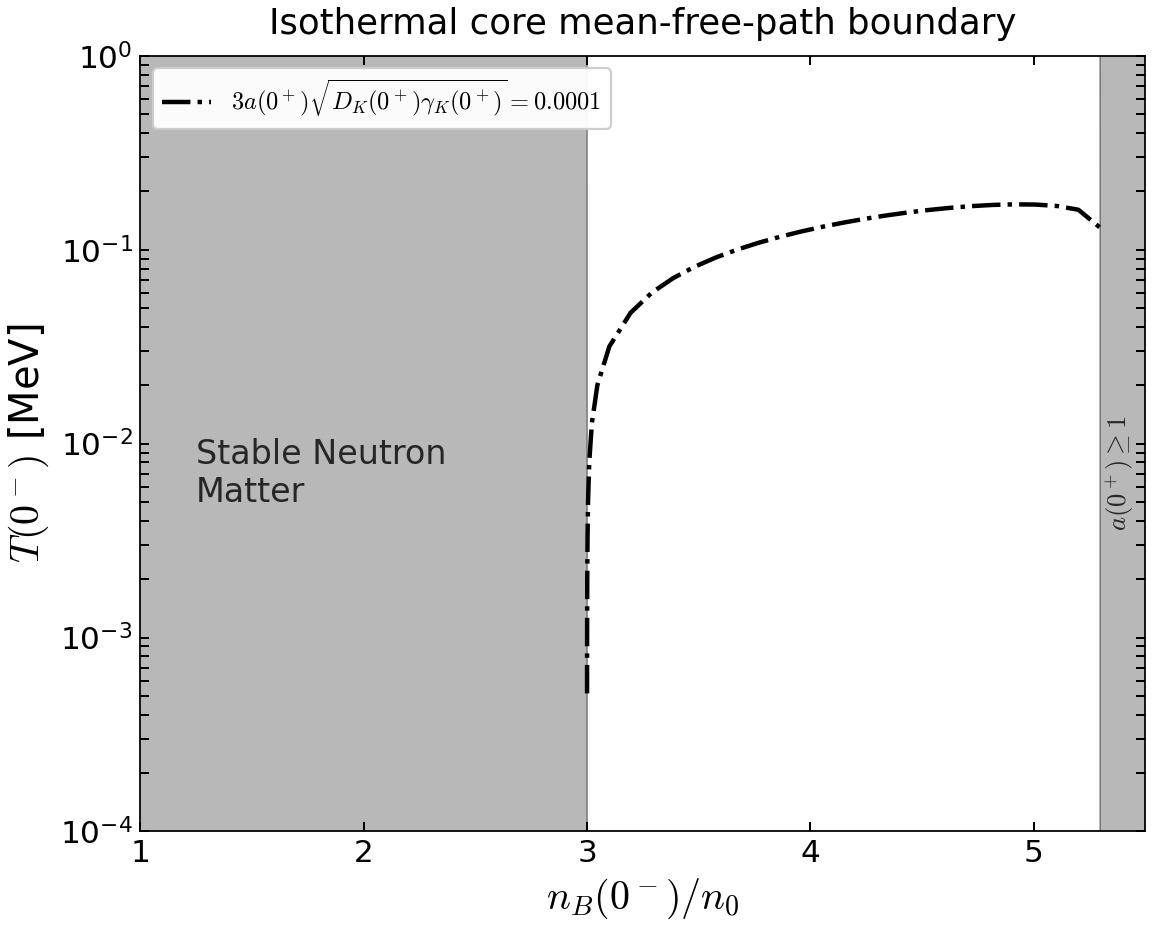

In [4]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 5.8)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BACKGROUND_COLOR = 'white'
X_LIMITS = (1., 5.5)
Y_LIMITS = (1.e-4, 1.)
X_SCALE = 'linear'
Y_SCALE = 'log'
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS = (1.e-4, 1.e-3, .01, .1, 1.)
TITLE = 'Isothermal core mean-free-path boundary'
TITLE_FONT_SIZE = 16
TITLE_PAD = 10
X_LABEL = r'$n_B(0^-)/n_0$'
Y_LABEL = r'$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 14
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
REGION_COLOR = '0.72'
REGION_ALPHA = 1.
REGION_ZORDER = 0
BOUNDARY_COLOR = '0.45'
BOUNDARY_LINE_WIDTH = .65
BOUNDARY_LINE_STYLE = '-'
BOUNDARY_ZORDER = 1
REGION_LABEL_COLOR = '0.15'
REGION_LABEL_FONT_SIZE = 15
STABLE_REGION_LABEL = 'Stable Neutron\nMatter'
STABLE_LABEL_POSITION = (1.25, .007)
STABLE_LABEL_HORIZONTAL_ALIGNMENT = 'left'
UPPER_REGION_LABEL = r'$a(0^+)\geq1$'
UPPER_LABEL_POSITION = (5.385, .007)
UPPER_LABEL_FONT_SIZE = 12
UPPER_LABEL_ROTATION = 90
UPPER_LABEL_HORIZONTAL_ALIGNMENT = 'center'
REGION_LABEL_VERTICAL_ALIGNMENT = 'center'
REGION_LABEL_ZORDER = 2
CURVE_COLOR = 'black'
LINE_STYLE = '-.'
LINE_WIDTH = 2.
CURVE_ZORDER = 3
ISOLATED_MARKER = 'o'
ISOLATED_MARKER_SIZE = 18.
CURVE_LABEL = (r'$3a(0^+)\sqrt{D_K(0^+)\gamma_K(0^+)}'
               rf"={core_result['identity']['fraction']:g}$")
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 11
LEGEND_FRAME_ALPHA = .95
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
SHOW_GRID = False
EXPORT_STEM = 'isothermal-core-mfp-f1e-4'
EXPORT_FORMATS = ('png', 'pdf')

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with plt.rc_context({'font.family': FONT_FAMILY, 'mathtext.fontset': MATH_FONT_SET, 'text.usetex': USE_TEX}):
    core_figure, core_axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                                         constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    core_axis.set_facecolor(BACKGROUND_COLOR)
    region_segments = isothermal_core_regions.segments(core_regions['rows'].values())
    for region in region_segments:
        if len(region) < 2:
            continue  # Do not shade across a failed temperature slice.
        region_T, region_lower, region_upper = region.T
        core_axis.fill_betweenx(region_T, X_LIMITS[0], region_lower,
                                facecolor=REGION_COLOR, alpha=REGION_ALPHA, zorder=REGION_ZORDER)
        core_axis.fill_betweenx(region_T, region_upper, X_LIMITS[1],
                                facecolor=REGION_COLOR, alpha=REGION_ALPHA, zorder=REGION_ZORDER)
        for boundary in (region_lower, region_upper):
            core_axis.plot(boundary, region_T, color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH,
                           linestyle=BOUNDARY_LINE_STYLE, zorder=BOUNDARY_ZORDER)
    core_axis.text(*STABLE_LABEL_POSITION, STABLE_REGION_LABEL, color=REGION_LABEL_COLOR,
                   fontsize=REGION_LABEL_FONT_SIZE, ha=STABLE_LABEL_HORIZONTAL_ALIGNMENT,
                   va=REGION_LABEL_VERTICAL_ALIGNMENT, zorder=REGION_LABEL_ZORDER)
    core_axis.text(*UPPER_LABEL_POSITION, UPPER_REGION_LABEL, color=REGION_LABEL_COLOR,
                   fontsize=UPPER_LABEL_FONT_SIZE, rotation=UPPER_LABEL_ROTATION,
                   ha=UPPER_LABEL_HORIZONTAL_ALIGNMENT, va=REGION_LABEL_VERTICAL_ALIGNMENT,
                   zorder=REGION_LABEL_ZORDER)
    core_segments = isothermal_core_mfp.segments(core_result['rows'].values())
    for segment in core_segments:
        if len(segment)>=2:
            core_axis.plot(segment[:,0],segment[:,1],color=CURVE_COLOR,linestyle=LINE_STYLE,
                           linewidth=LINE_WIDTH,zorder=CURVE_ZORDER)
        else:
            core_axis.scatter(segment[:,0],segment[:,1],color=CURVE_COLOR,marker=ISOLATED_MARKER,
                              s=ISOLATED_MARKER_SIZE,zorder=CURVE_ZORDER)
    core_axis.set(xlim=X_LIMITS,ylim=Y_LIMITS,xscale=X_SCALE,yscale=Y_SCALE)
    core_axis.set_xticks(X_TICKS)
    core_axis.set_yticks(Y_TICKS)
    core_axis.set_xlabel(X_LABEL,fontsize=AXIS_LABEL_FONT_SIZE)
    core_axis.set_ylabel(Y_LABEL,fontsize=AXIS_LABEL_FONT_SIZE)
    core_axis.set_title(TITLE,fontsize=TITLE_FONT_SIZE,pad=TITLE_PAD)
    core_axis.tick_params(which='both',direction=TICK_DIRECTION,top=TICKS_TOP,right=TICKS_RIGHT,
                          length=TICK_LENGTH,width=TICK_WIDTH,labelsize=TICK_LABEL_FONT_SIZE)
    for spine in core_axis.spines.values(): spine.set_linewidth(SPINE_LINE_WIDTH)
    core_axis.grid(SHOW_GRID)
    if core_segments:
        core_axis.legend(handles=[Line2D([],[],color=CURVE_COLOR,linestyle=LINE_STYLE,
                                         linewidth=LINE_WIDTH,label=CURVE_LABEL)],
                         loc=LEGEND_LOCATION,fontsize=LEGEND_FONT_SIZE,framealpha=LEGEND_FRAME_ALPHA,
                         facecolor=LEGEND_FACE_COLOR,edgecolor=LEGEND_EDGE_COLOR)
    for extension in EXPORT_FORMATS:
        core_path=CORE_OUTPUT_DIRECTORY/f'{EXPORT_STEM}.{extension}'
        core_figure.savefig(core_path,dpi=EXPORT_DPI,facecolor=BACKGROUND_COLOR)
        print('Saved',core_path.relative_to(CORE_ROOT))
    plt.show()


## Nearly Constant Baryon Chemical Potential: Original Profile Figure

The original plotting code is in `26-04-09.ipynb`, cell 9 (zero based), and its stored output matches the requested figure.
The upstream calculation cell was later changed to a different run, so executing that old notebook from the top does not reproduce the stored figure.
The cell below redraws the original contour vertices, four sampled profile points, and endpoints recovered from the saved **vector PDF**, `jargon/entropy_tqguess_uagrad_pi_qm_contour.pdf`.
This is a faithful replot of a historical EOS/solver result, not a new BVP calculation or a validation with the current EOS.

All endpoint labels use $x=0^-$, $x=0^+$, and $x=\infty$.
The fixed quantity is the momentum flux $\Pi=P+hu^2$; the colored curves are different temperature slices at the same flux.
The nearly vertical numerical path supports neglecting the change in $\mu_B$ **for this example**: the plotted endpoint change is about $0.073\,\mathrm{MeV}$, or $0.0064\%$.
This percentage is reconstructed at vector-figure precision and is not a bound for every front in the parameter scan.
All visual controls are in the tuning block, and the cell runs from the saved JSON without importing a solver.


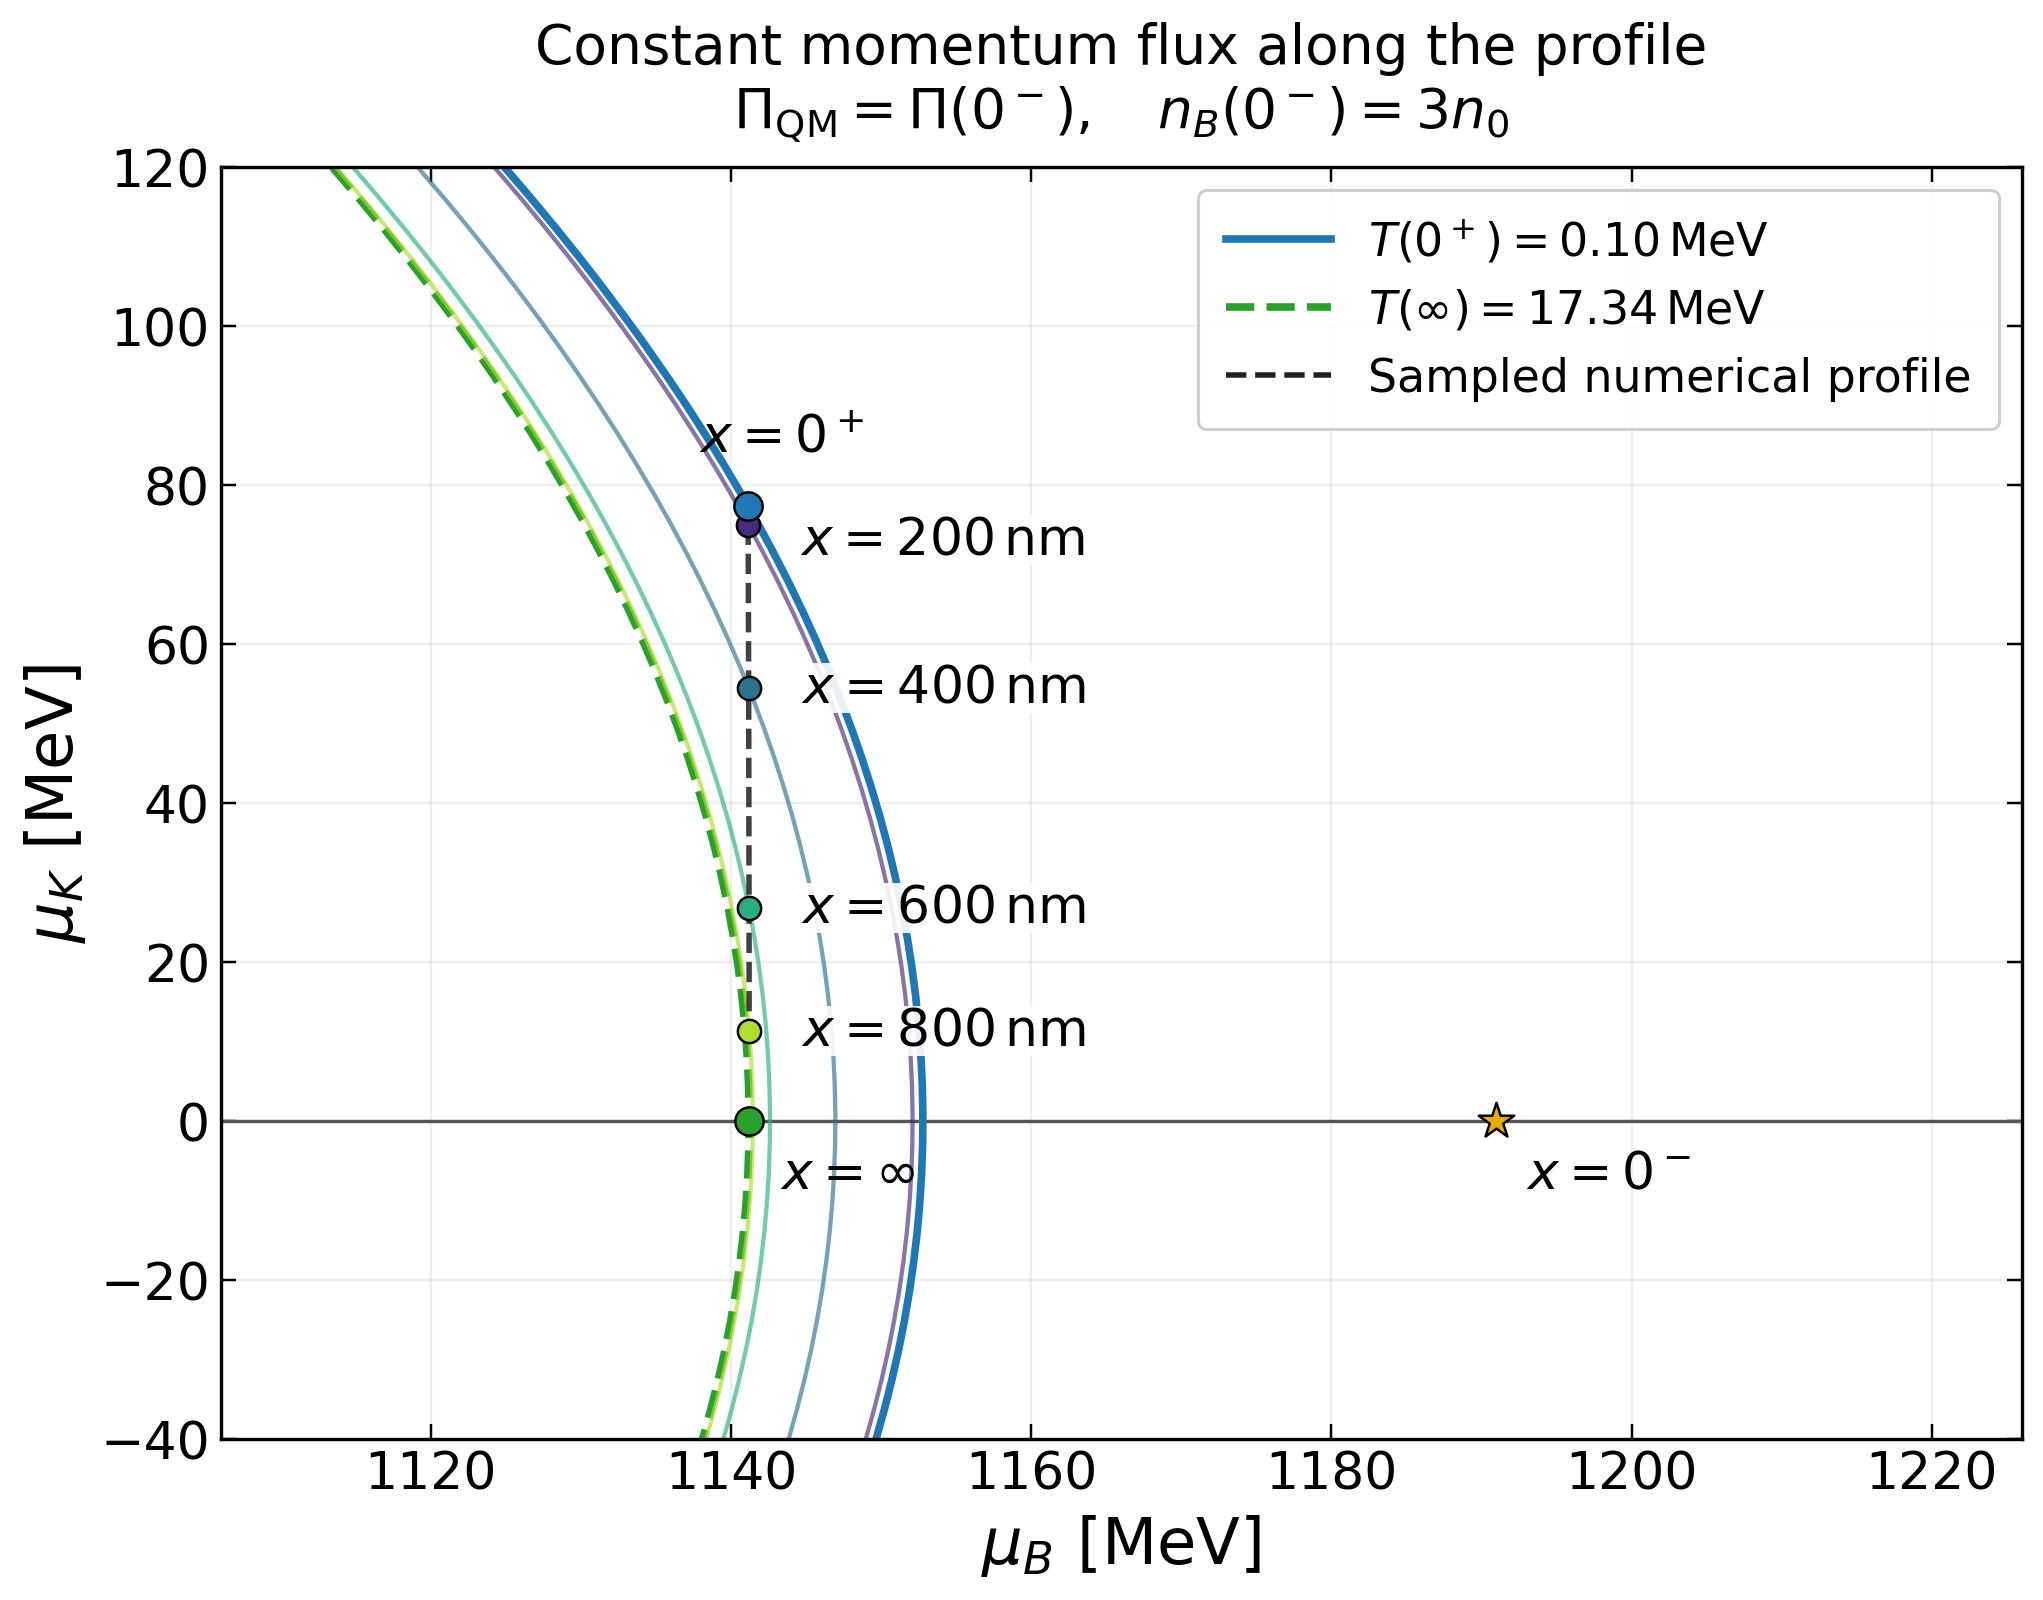

Original source: 26-04-09.ipynb, cell 9 (zero based).
Replotted archived PDF vector coordinates; no new EOS/BVP calculation.
Endpoint mu_B: 1141.13 -> 1141.21 MeV
Endpoint change: 0.073 MeV (0.0064%)
This is one historical profile, not a uniform error bound on constant mu_B.
Saved: local_analysis_results/26-10-14/constant-momentum-profile.png, local_analysis_results/26-10-14/constant-momentum-profile.pdf, 26-10-14.assets/constant-momentum-profile.png


In [1]:
# Tunable plotting parameters
DATA_FILE = "local_analysis_results/26-10-14/constant-momentum-profile-data.json"
OUTPUT_PNG = "local_analysis_results/26-10-14/constant-momentum-profile.png"
OUTPUT_PDF = "local_analysis_results/26-10-14/constant-momentum-profile.pdf"
MEETING_PNG = "26-10-14.assets/constant-momentum-profile.png"
FIGURE_SIZE = (9.4, 7.4)
FIGURE_DPI = 160
EXPORT_DPI = 220
TITLE_FONT_SIZE = 18
AXIS_LABEL_FONT_SIZE = 21
TICK_LABEL_FONT_SIZE = 17
LEGEND_FONT_SIZE = 15
ANNOTATION_FONT_SIZE = 17
FONT_FAMILY = "DejaVu Sans"
MATH_FONT_SET = "dejavusans"
X_LIMITS = (1106., 1226.)
Y_LIMITS = (-40., 120.)
X_TICKS = (1120., 1140., 1160., 1180., 1200., 1220.)
Y_TICKS = (-40., -20., 0., 20., 40., 60., 80., 100., 120.)
TICK_DIRECTION = "in"
TOP_TICKS = True
RIGHT_TICKS = True
TICK_LENGTH = 5
GRID_ALPHA = 0.2
GRID_LINE_WIDTH = 0.8
AXIS_LINE_WIDTH = 1.1
REFERENCE_COLOR = "#555555"
REFERENCE_LINE_WIDTH = 1.1
REFERENCE_LINE_STYLE = "-"
COLOR_0PLUS = "#1f77b4"
COLOR_INF = "#2ca02c"
COLOR_0MINUS = "#e6ad00"
ENDPOINT_LINE_WIDTH = 2.5
LINE_STYLE_0PLUS = "-"
LINE_STYLE_INF = "--"
SAMPLE_COLORS = ("#472a7a", "#2c728e", "#28ae80", "#b0dd2f")
SLICE_LINE_WIDTH = 1.4
SLICE_LINE_STYLE = "-"
SLICE_ALPHA = 0.65
PROFILE_COLOR = "#202020"
PROFILE_LINE_WIDTH = 1.8
PROFILE_LINE_STYLE = "--"
PROFILE_ALPHA = 0.85
POINT_EDGE_COLOR = "black"
POINT_EDGE_LINE_WIDTH = 0.8
SAMPLE_MARKER = "o"
SAMPLE_MARKER_SIZE = 58
ENDPOINT_MARKER = "o"
ENDPOINT_MARKER_SIZE = 86
UPSTREAM_MARKER = "*"
UPSTREAM_MARKER_SIZE = 150
LINE_ZORDER = 2
PROFILE_ZORDER = 3
SAMPLE_ZORDER = 4
ENDPOINT_ZORDER = 5
OFFSET_0PLUS = (-16, 18)
OFFSET_INF = (10, -22)
OFFSET_0MINUS = (10, -22)
SAMPLE_LABEL_OFFSETS = ((17, -5), (17, 0), (17, 0), (17, 0))
ANNOTATION_BOX_ALPHA = 0.9
ANNOTATION_BOX_COLOR = "white"
ANNOTATION_BOX_PAD = 0.08
LEGEND_LOCATION = "upper right"
LEGEND_FRAME_ALPHA = 0.94
LEGEND_HANDLE_LENGTH = 2.3
LEGEND_BORDER_PAD = 0.6
TITLE_PAD = 13
LAYOUT_PAD = 1.1
EXPORT_BOUNDING_BOX = "tight"
EXPORT_TRANSPARENT = False
X_AXIS_LABEL = r"$\mu_B\ [\mathrm{MeV}]$"
Y_AXIS_LABEL = r"$\mu_K\ [\mathrm{MeV}]$"
LABEL_0PLUS = r"$x=0^+$"
LABEL_INF = r"$x=\infty$"
LABEL_0MINUS = r"$x=0^-$"

import json
from pathlib import Path
import shutil

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

data = json.loads(Path(DATA_FILE).read_text())
style = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET,
         "axes.linewidth": AXIS_LINE_WIDTH}
with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
    ax.axhline(0., color=REFERENCE_COLOR, linewidth=REFERENCE_LINE_WIDTH,
               linestyle=REFERENCE_LINE_STYLE)
    for key, color, line_style in (("contour_0plus", COLOR_0PLUS, LINE_STYLE_0PLUS),
                                    ("contour_inf", COLOR_INF, LINE_STYLE_INF)):
        points = np.asarray(data[key])
        ax.plot(points[:, 0], points[:, 1], color=color,
                linewidth=ENDPOINT_LINE_WIDTH, linestyle=line_style, zorder=LINE_ZORDER)
    for contour, color in zip(data["contours_sample"], SAMPLE_COLORS):
        points = np.asarray(contour)
        ax.plot(points[:, 0], points[:, 1], color=color, linewidth=SLICE_LINE_WIDTH,
                linestyle=SLICE_LINE_STYLE, alpha=SLICE_ALPHA, zorder=LINE_ZORDER)
    path = np.asarray(data["profile_path"])
    ax.plot(path[:, 0], path[:, 1], color=PROFILE_COLOR, linewidth=PROFILE_LINE_WIDTH,
            linestyle=PROFILE_LINE_STYLE, alpha=PROFILE_ALPHA, zorder=PROFILE_ZORDER)
    for point, x_nm, color, offset in zip(data["sample_points"], data["sample_x_nm"],
                                          SAMPLE_COLORS, SAMPLE_LABEL_OFFSETS):
        ax.scatter(*point, s=SAMPLE_MARKER_SIZE, marker=SAMPLE_MARKER, color=color,
                   edgecolor=POINT_EDGE_COLOR, linewidths=POINT_EDGE_LINE_WIDTH,
                   zorder=SAMPLE_ZORDER)
        ax.annotate(rf"$x={x_nm:.0f}\,\mathrm{{nm}}$", point, xytext=offset,
                    textcoords="offset points", fontsize=ANNOTATION_FONT_SIZE,
                    va="center", bbox={"facecolor": ANNOTATION_BOX_COLOR, "edgecolor": "none",
                                       "alpha": ANNOTATION_BOX_ALPHA, "pad": ANNOTATION_BOX_PAD})
    for key, color, marker, size, label, offset in (
        ("point_0plus", COLOR_0PLUS, ENDPOINT_MARKER, ENDPOINT_MARKER_SIZE, LABEL_0PLUS, OFFSET_0PLUS),
        ("point_inf", COLOR_INF, ENDPOINT_MARKER, ENDPOINT_MARKER_SIZE, LABEL_INF, OFFSET_INF),
        ("point_0minus", COLOR_0MINUS, UPSTREAM_MARKER, UPSTREAM_MARKER_SIZE, LABEL_0MINUS, OFFSET_0MINUS),
    ):
        point = data[key]
        ax.scatter(*point, s=size, marker=marker, color=color, edgecolor=POINT_EDGE_COLOR,
                   linewidths=POINT_EDGE_LINE_WIDTH, zorder=ENDPOINT_ZORDER)
        ax.annotate(label, point, xytext=offset, textcoords="offset points",
                    fontsize=ANNOTATION_FONT_SIZE)

    handles = [
        Line2D([], [], color=COLOR_0PLUS, linewidth=ENDPOINT_LINE_WIDTH, linestyle=LINE_STYLE_0PLUS,
               label=rf"$T(0^+)={data['T_0plus_MeV']:.2f}\,\mathrm{{MeV}}$"),
        Line2D([], [], color=COLOR_INF, linewidth=ENDPOINT_LINE_WIDTH, linestyle=LINE_STYLE_INF,
               label=rf"$T(\infty)={data['T_inf_MeV']:.2f}\,\mathrm{{MeV}}$"),
        Line2D([], [], color=PROFILE_COLOR, linewidth=PROFILE_LINE_WIDTH,
               linestyle=PROFILE_LINE_STYLE, label="Sampled numerical profile"),
    ]
    ax.legend(handles=handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
              framealpha=LEGEND_FRAME_ALPHA, handlelength=LEGEND_HANDLE_LENGTH,
              borderpad=LEGEND_BORDER_PAD)
    ax.set_title("Constant momentum flux along the profile\n"
                 r"$\Pi_{\rm QM}=\Pi(0^-),\quad n_B(0^-)=3n_0$",
                 fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    ax.set_xlim(X_LIMITS)
    ax.set_ylim(Y_LIMITS)
    ax.set_xticks(X_TICKS)
    ax.set_yticks(Y_TICKS)
    ax.ticklabel_format(style="plain", axis="x", useOffset=False)
    ax.tick_params(which="both", direction=TICK_DIRECTION, top=TOP_TICKS,
                   right=RIGHT_TICKS, length=TICK_LENGTH, labelsize=TICK_LABEL_FONT_SIZE)
    ax.grid(alpha=GRID_ALPHA, linewidth=GRID_LINE_WIDTH)
    fig.tight_layout(pad=LAYOUT_PAD)
    for filename in (OUTPUT_PNG, OUTPUT_PDF):
        destination = Path(filename)
        destination.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destination, dpi=EXPORT_DPI, bbox_inches=EXPORT_BOUNDING_BOX,
                    transparent=EXPORT_TRANSPARENT)
    Path(MEETING_PNG).parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(OUTPUT_PNG, MEETING_PNG)
    plt.show()

muB_0plus = data["point_0plus"][0]
muB_inf = data["point_inf"][0]
print("Original source: 26-04-09.ipynb, cell 9 (zero based).")
print("Replotted archived PDF vector coordinates; no new EOS/BVP calculation.")
print(f"Endpoint mu_B: {muB_0plus:.2f} -> {muB_inf:.2f} MeV")
print(f"Endpoint change: {muB_inf-muB_0plus:.3f} MeV ({100*(muB_inf/muB_0plus-1):.4f}%)")
print("This is one historical profile, not a uniform error bound on constant mu_B.")
print(f"Saved: {OUTPUT_PNG}, {OUTPUT_PDF}, {MEETING_PNG}")


## Accuracy of the Isothermal Composition Ceiling: Eq. (35)

The exact neutral-EOS ceiling is the reference on every panel and the horizontal coordinate.
The upper panel compares composition values; the middle panel shows the signed difference; the lower panel shows the relative difference with the exact ceiling in the denominator.

The 292 colored points come from the [independently verified audit](local_analysis_results/26-10-16/aiso-accuracy/results.json), covering successful targets in the original seven-level isothermal checkpoint, with temperatures from 0.01 to 83.86 MeV.
Temperature sets the marker color; the points are not connected or presented as fixed-temperature curves.
The blue dashed line is the exact cold-isobar relation substituted into Eq. (35); its 1% crossing at exact composition 0.495544 was checked with Wolfram.
The black reference is the identity in the upper panel and zero in the difference panels.

There are 113 points above 1% error, with a largest error of 8.48%.
The static expansion uses the equilibrated-endpoint baryon chemical potential, not the interface value.
The production solver already computes the ceiling from the exact EOS; this figure checks the manuscript's explicit approximation, not the accuracy of the numerical front speed.

Run the following cell independently from the repository root; it loads saved results and exports PNG/PDF without new EOS or BVP solves.
Plot settings, fonts, and output paths are at the top of the cell.


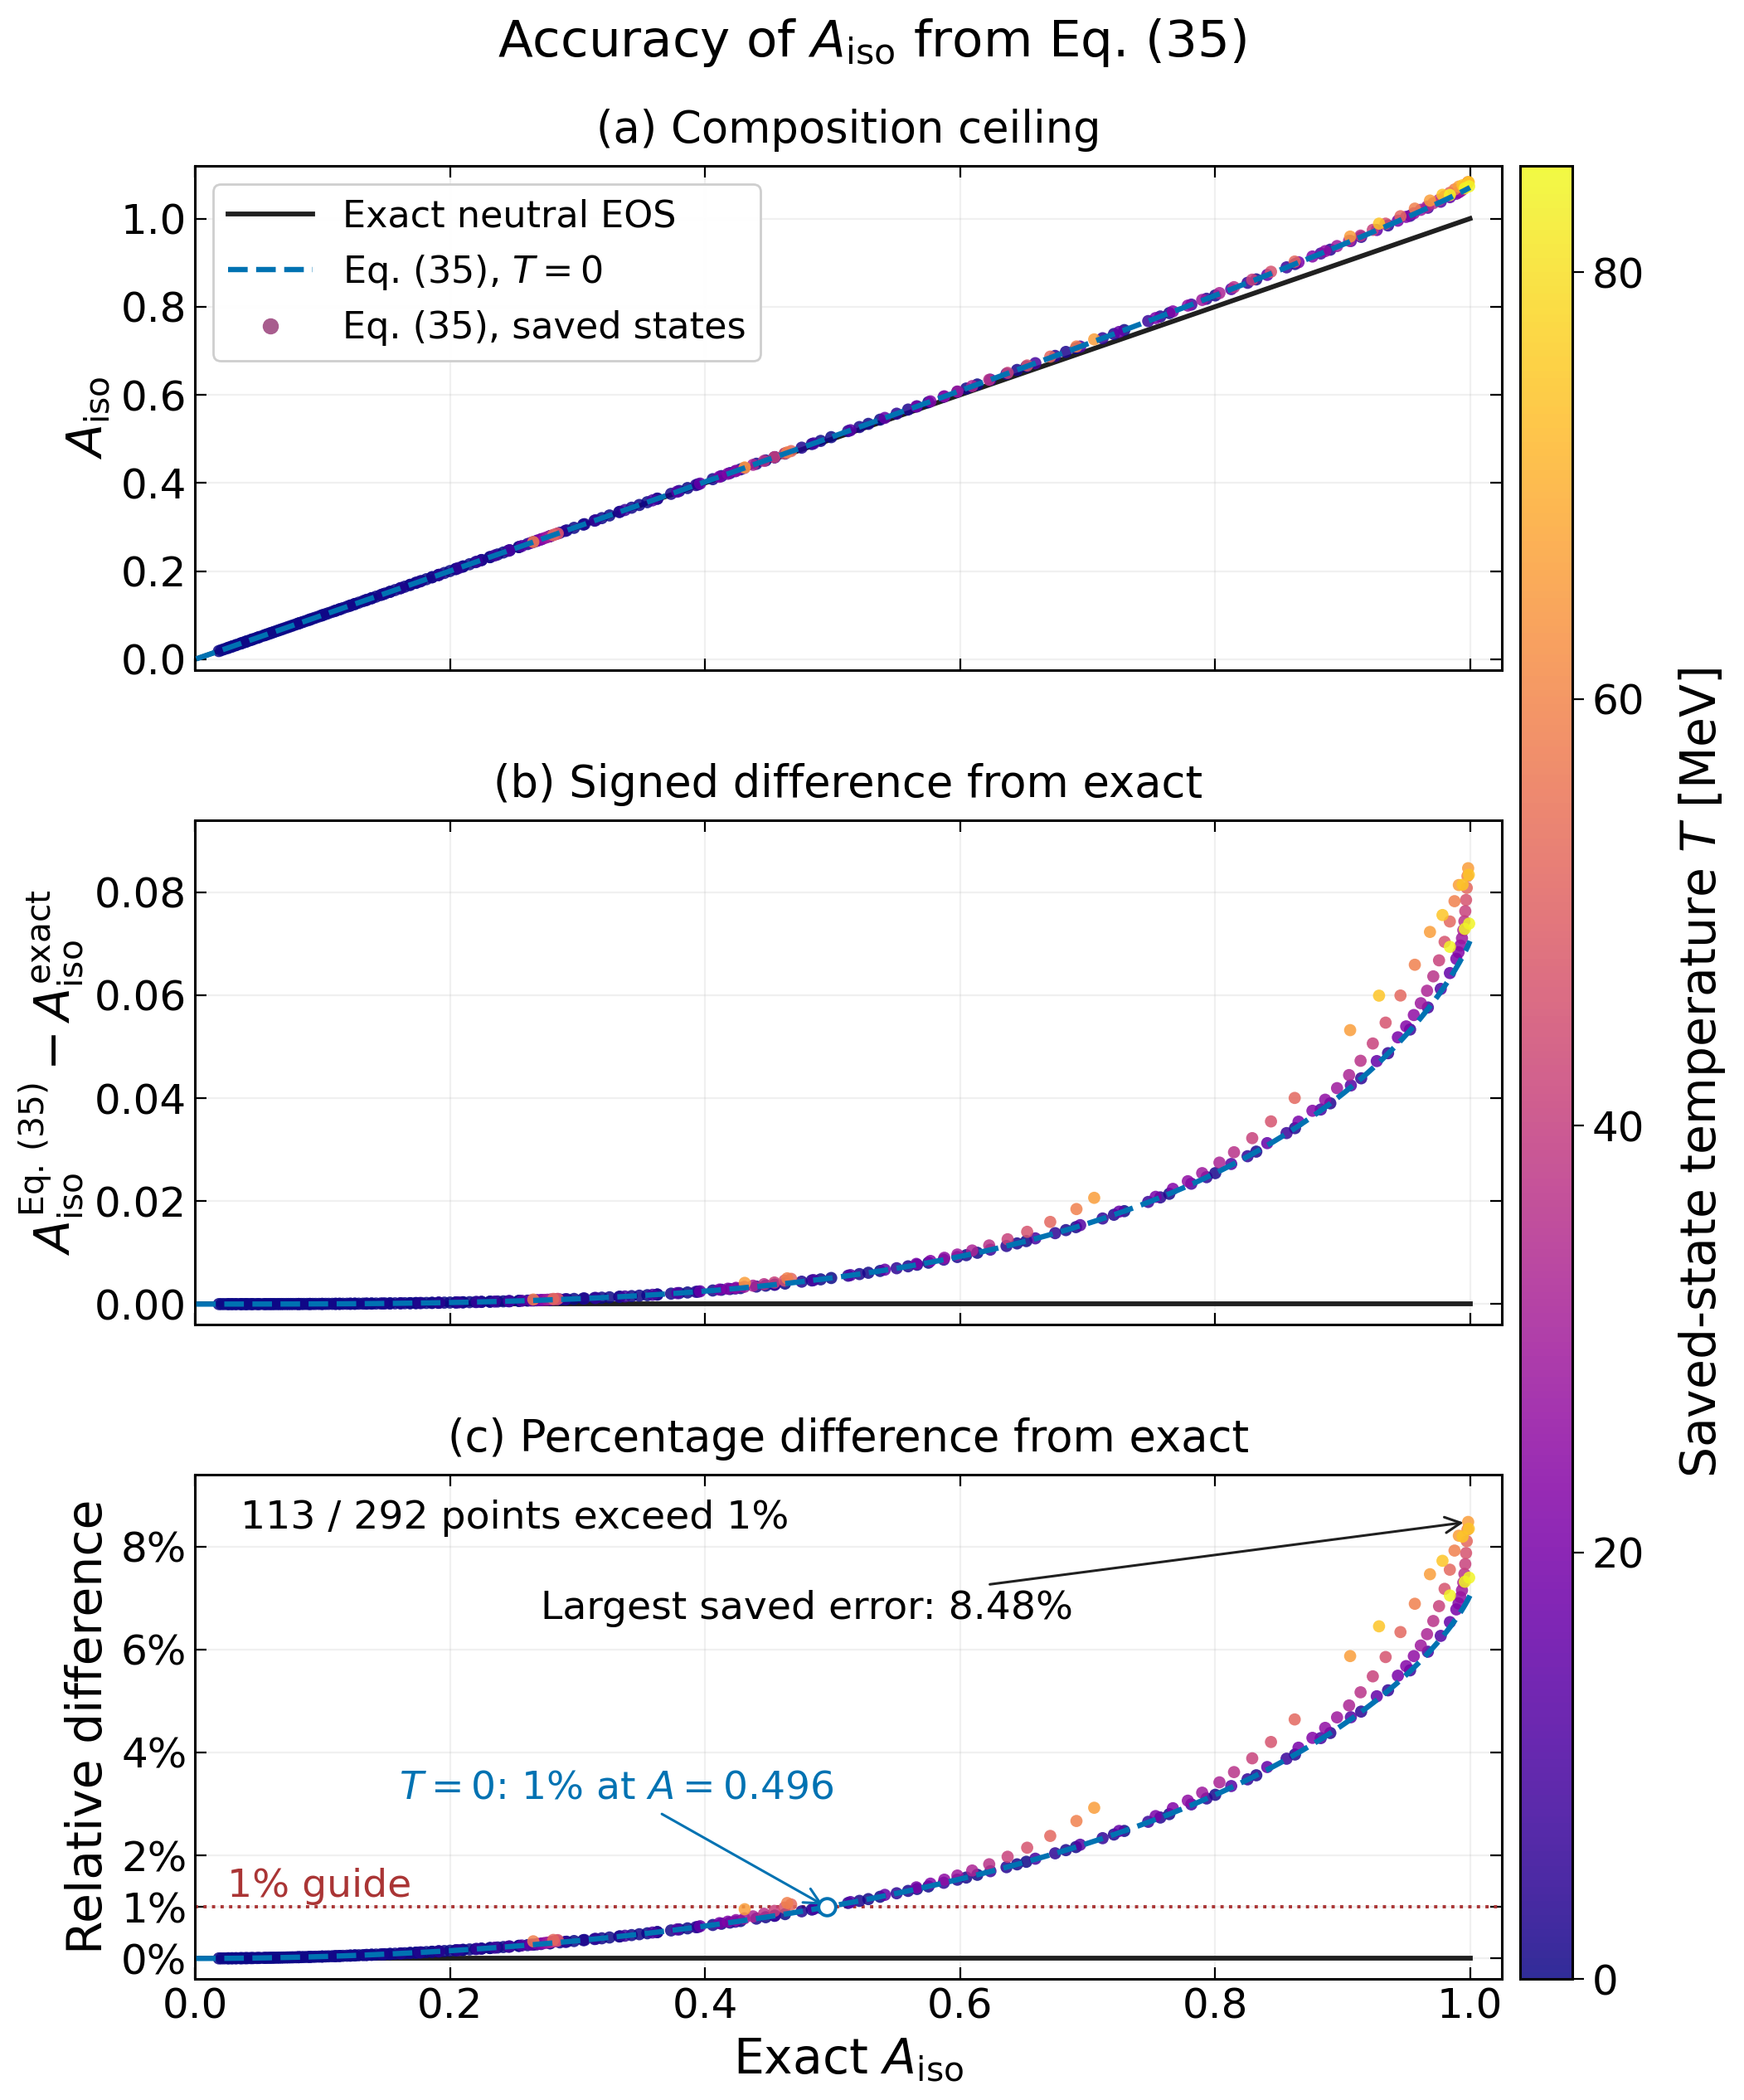

Exact-EOS baseline; 292 audited states, no new EOS/BVP solves.
Relative error = 100*(A_Eq35/A_exact - 1); 113 points exceed 1%.
Largest saved error: 8.47673%; A_exact=0.99855028, A_Eq35=1.08319473.
Exports: local_analysis_results/26-10-14/aiso-accuracy.png, local_analysis_results/26-10-14/aiso-accuracy.pdf, 26-10-14.assets/aiso-accuracy.png


In [1]:
# Tunable plotting parameters
DATA_FILE = "local_analysis_results/26-10-16/aiso-accuracy/results.json"
OUTPUT_PNG = "local_analysis_results/26-10-14/aiso-accuracy.png"
OUTPUT_PDF = "local_analysis_results/26-10-14/aiso-accuracy.pdf"
MEETING_PNG = "26-10-14.assets/aiso-accuracy.png"
FIGURE_SIZE = (10.4, 12.7)
FIGURE_DPI = 150
EXPORT_DPI = 200
TITLE_FONT_SIZE = 22
PANEL_TITLE_FONT_SIZE = 19
AXIS_LABEL_FONT_SIZE = 21
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 16
ANNOTATION_FONT_SIZE = 17
FONT_FAMILY = "DejaVu Sans"
MATH_FONT_SET = "dejavusans"
AXIS_LINE_WIDTH = 1.1
AXIS_SCALE = "linear"
X_LIMITS = (0., 1.025)
X_TICKS = (0., 0.2, 0.4, 0.6, 0.8, 1.)
Y_LIMITS = ((-0.025, 1.12), (-0.004, 0.094), (-0.4, 9.4))
Y_TICKS = ((0., 0.2, 0.4, 0.6, 0.8, 1.), (0., 0.02, 0.04, 0.06, 0.08), (0., 1., 2., 4., 6., 8.))
X_AXIS_LABEL = r"Exact $A_{\rm iso}$"
Y_AXIS_LABELS = (r"$A_{\rm iso}$", r"$A_{\rm iso}^{\rm Eq.\,(35)}-A_{\rm iso}^{\rm exact}$", "Relative difference")
PANEL_TITLES = ("(a) Composition ceiling", "(b) Signed difference from exact", "(c) Percentage difference from exact")
TITLE_PAD = 10
TICK_DIRECTION = "in"
TOP_TICKS = True
RIGHT_TICKS = True
TICK_LENGTH = 5
GRID_ALPHA = 0.18
GRID_LINE_WIDTH = 0.8
BASELINE_COLOR = "#202020"
BASELINE_LINE_WIDTH = 2.1
BASELINE_LINE_STYLE = "-"
BASELINE_ZORDER = 2
COLD_COLOR = "#0072B2"
COLD_LINE_WIDTH = 2.3
COLD_LINE_STYLE = "--"
COLD_ZORDER = 4
COLD_A_MIN = 0.001
COLD_A_MAX = 1.
COLD_SAMPLE_COUNT = 601
POINT_COLORMAP = "plasma"
POINT_MARKER = "o"
POINT_SIZE = 28
POINT_ALPHA = 0.85
POINT_EDGE_COLOR = "none"
POINT_ZORDER = 3
TEMPERATURE_LIMITS = (0., 85.)
COLORBAR_TICKS = (0., 20., 40., 60., 80.)
COLORBAR_WIDTH_RATIO = 0.04
COLORBAR_LABEL_PAD = 14
PERCENT_TICK_DECIMALS = 0
GUIDE_PERCENT = 1.
GUIDE_COLOR = "#aa3535"
GUIDE_LINE_WIDTH = 1.4
GUIDE_LINE_STYLE = ":"
GUIDE_LABEL_POSITION = (0.025, 1.2)
ANNOTATION_ARROW_STYLE = "->"
ANNOTATION_LINE_WIDTH = 1.1
COLD_CROSSING_MARKER = "o"
COLD_CROSSING_MARKER_SIZE = 55
COLD_CROSSING_EDGE_WIDTH = 1.4
COLD_CROSSING_FACE_COLOR = "white"
COLD_CROSSING_LABEL_POSITION = (0.16, 3.1)
MAXIMUM_LABEL_POSITION = (0.48, 6.6)
COUNT_LABEL_POSITION = (0.035, 0.95)
LEGEND_LOCATION = "upper left"
LEGEND_FRAME_ALPHA = 0.95
LEGEND_HANDLE_LENGTH = 2.3
LEGEND_POINT_COLOR = "#a85d8e"
LEGEND_MARKER_SIZE = 6
LAYOUT_MODE = "constrained"
LAYOUT_VERTICAL_PAD = 0.12
EXPORT_BOUNDING_BOX = "tight"
EXPORT_TRANSPARENT = False
SHOW_FIGURE = True

import json
from pathlib import Path
import shutil

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np

audit = json.loads(Path(DATA_FILE).read_text())
summary, rows = audit["summary"], audit["rows"]
a_exact = np.array([row["A_exact"] for row in rows])
a_eq35 = np.array([row["A_taylor"] for row in rows])
temperature = np.array([row["T_MeV"] for row in rows])
difference = a_eq35 - a_exact
percent_difference = 100 * difference / a_exact
assert np.all(a_exact > 0) and np.all(a_exact <= 1)
assert len(rows) == summary["count"]
assert np.allclose(percent_difference, [row["relative_error_percent"] for row in rows], atol=1e-11, rtol=0)
assert np.count_nonzero(np.abs(percent_difference) > 1) == summary["count_above_one_percent"]
assert np.min(temperature) >= TEMPERATURE_LIMITS[0] and np.max(temperature) <= TEMPERATURE_LIMITS[1]

cold_a = np.linspace(COLD_A_MIN, COLD_A_MAX, COLD_SAMPLE_COUNT)
# Exact cold isobar/Gibbs relation, substituted into the Taylor ceiling.
cold_eq35 = 3 * np.sqrt(((1 + (1 + cold_a)**(4/3) + (1 - cold_a)**(4/3)) / 3)**(3/4) - 1)
cold_difference = cold_eq35 - cold_a
cold_percent = 100 * cold_difference / cold_a
cold_one_percent_a = 0.49554417610308704  # Verified in the audit's verification.wl.
maximum_index = int(np.argmax(percent_difference))

style = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET,
         "axes.linewidth": AXIS_LINE_WIDTH}
with plt.rc_context(style):
    fig = plt.figure(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, layout=LAYOUT_MODE)
    fig.get_layout_engine().set(h_pad=LAYOUT_VERTICAL_PAD)
    grid = fig.add_gridspec(3, 2, width_ratios=(1, COLORBAR_WIDTH_RATIO))
    axes = [fig.add_subplot(grid[0, 0])]
    axes.extend(fig.add_subplot(grid[i, 0], sharex=axes[0]) for i in (1, 2))
    color_axis = fig.add_subplot(grid[:, 1])
    normalization = Normalize(*TEMPERATURE_LIMITS)
    exact_values = (cold_a, np.zeros_like(cold_a), np.zeros_like(cold_a))
    cold_values = (cold_eq35, cold_difference, cold_percent)
    saved_values = (a_eq35, difference, percent_difference)
    for index, axis in enumerate(axes):
        axis.plot(cold_a, exact_values[index], color=BASELINE_COLOR,
                  linewidth=BASELINE_LINE_WIDTH, linestyle=BASELINE_LINE_STYLE,
                  zorder=BASELINE_ZORDER, label="Exact neutral EOS")
        points = axis.scatter(a_exact, saved_values[index], c=temperature,
                              cmap=POINT_COLORMAP, norm=normalization,
                              s=POINT_SIZE, marker=POINT_MARKER, alpha=POINT_ALPHA,
                              edgecolors=POINT_EDGE_COLOR, zorder=POINT_ZORDER)
        axis.plot(cold_a, cold_values[index], color=COLD_COLOR,
                  linewidth=COLD_LINE_WIDTH, linestyle=COLD_LINE_STYLE,
                  zorder=COLD_ZORDER, label=r"Eq. (35), $T=0$")
        axis.set_title(PANEL_TITLES[index], fontsize=PANEL_TITLE_FONT_SIZE, pad=TITLE_PAD)
        axis.set_ylabel(Y_AXIS_LABELS[index], fontsize=AXIS_LABEL_FONT_SIZE)
        axis.set_xlim(X_LIMITS)
        axis.set_ylim(Y_LIMITS[index])
        axis.set_xscale(AXIS_SCALE)
        axis.set_yscale(AXIS_SCALE)
        axis.set_xticks(X_TICKS)
        axis.set_yticks(Y_TICKS[index])
        axis.tick_params(which="both", direction=TICK_DIRECTION, top=TOP_TICKS,
                         right=RIGHT_TICKS, length=TICK_LENGTH,
                         labelsize=TICK_LABEL_FONT_SIZE, labelbottom=index == 2)
        axis.grid(alpha=GRID_ALPHA, linewidth=GRID_LINE_WIDTH)
    axes[-1].set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axes[-1].yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=PERCENT_TICK_DECIMALS))
    axes[-1].axhline(GUIDE_PERCENT, color=GUIDE_COLOR, linewidth=GUIDE_LINE_WIDTH,
                    linestyle=GUIDE_LINE_STYLE, zorder=BASELINE_ZORDER)
    axes[-1].text(*GUIDE_LABEL_POSITION, f"{GUIDE_PERCENT:g}% guide", color=GUIDE_COLOR,
                 fontsize=ANNOTATION_FONT_SIZE)
    axes[-1].scatter(cold_one_percent_a, 1., marker=COLD_CROSSING_MARKER,
                    s=COLD_CROSSING_MARKER_SIZE, facecolor=COLD_CROSSING_FACE_COLOR, edgecolor=COLD_COLOR,
                    linewidths=COLD_CROSSING_EDGE_WIDTH, zorder=COLD_ZORDER + 1)
    axes[-1].annotate(r"$T=0$: 1% at $A=0.496$", (cold_one_percent_a, 1.),
                     xytext=COLD_CROSSING_LABEL_POSITION, fontsize=ANNOTATION_FONT_SIZE,
                     color=COLD_COLOR, arrowprops={"arrowstyle": ANNOTATION_ARROW_STYLE,
                                                  "color": COLD_COLOR, "lw": ANNOTATION_LINE_WIDTH})
    axes[-1].annotate(f"Largest saved error: {percent_difference[maximum_index]:.2f}%",
                     (a_exact[maximum_index], percent_difference[maximum_index]),
                     xytext=MAXIMUM_LABEL_POSITION, fontsize=ANNOTATION_FONT_SIZE,
                     ha="center", arrowprops={"arrowstyle": ANNOTATION_ARROW_STYLE,
                                               "color": BASELINE_COLOR, "lw": ANNOTATION_LINE_WIDTH})
    axes[-1].text(*COUNT_LABEL_POSITION,
                 f"{summary['count_above_one_percent']} / {len(rows)} points exceed 1%",
                 transform=axes[-1].transAxes, va="top", fontsize=ANNOTATION_FONT_SIZE)
    handles = [
        Line2D([], [], color=BASELINE_COLOR, linewidth=BASELINE_LINE_WIDTH,
               linestyle=BASELINE_LINE_STYLE, label="Exact neutral EOS"),
        Line2D([], [], color=COLD_COLOR, linewidth=COLD_LINE_WIDTH,
               linestyle=COLD_LINE_STYLE, label=r"Eq. (35), $T=0$"),
        Line2D([], [], color=LEGEND_POINT_COLOR, marker=POINT_MARKER, linestyle="none",
               markersize=LEGEND_MARKER_SIZE, label="Eq. (35), saved states"),
    ]
    axes[0].legend(handles=handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
                   framealpha=LEGEND_FRAME_ALPHA, handlelength=LEGEND_HANDLE_LENGTH)
    colorbar = fig.colorbar(points, cax=color_axis, ticks=COLORBAR_TICKS)
    colorbar.set_label(r"Saved-state temperature $T$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE,
                       labelpad=COLORBAR_LABEL_PAD)
    colorbar.ax.tick_params(labelsize=TICK_LABEL_FONT_SIZE, length=TICK_LENGTH)
    fig.suptitle(r"Accuracy of $A_{\rm iso}$ from Eq. (35)", fontsize=TITLE_FONT_SIZE)
    for filename in (OUTPUT_PNG, OUTPUT_PDF):
        destination = Path(filename)
        destination.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destination, dpi=EXPORT_DPI, bbox_inches=EXPORT_BOUNDING_BOX,
                    transparent=EXPORT_TRANSPARENT)
    Path(MEETING_PNG).parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(OUTPUT_PNG, MEETING_PNG)
    if SHOW_FIGURE:
        plt.show()

print(f"Exact-EOS baseline; {len(rows)} audited states, no new EOS/BVP solves.")
print(f"Relative error = 100*(A_Eq35/A_exact - 1); {summary['count_above_one_percent']} points exceed 1%.")
print(f"Largest saved error: {percent_difference[maximum_index]:.5f}%; "
      f"A_exact={a_exact[maximum_index]:.8f}, A_Eq35={a_eq35[maximum_index]:.8f}.")
print(f"Exports: {OUTPUT_PNG}, {OUTPUT_PDF}, {MEETING_PNG}")
